# 4A. CBOW Word2Vec - IMDB Sentiment
Train gensim Word2Vec (sg=0 = CBOW), average embeddings per doc, classify.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
df = pd.read_csv("../datasets/CBOW/IMDB Dataset.csv")
df = df.sample(10000, random_state=42).reset_index(drop=True)
y = (df["sentiment"] == "positive").astype(int).to_numpy()

sentences = []
for review in df["review"]:
    tokens = re.findall(r"[a-z]+", review.lower())
    sentences.append(tokens)

print("docs:", len(sentences), "example:", sentences[0][:10])

docs: 10000 example: ['i', 'really', 'liked', 'this', 'summerslam', 'due', 'to', 'the', 'look', 'of']


In [3]:
w2v = Word2Vec(sentences, sg=0)
print("vocab:", len(w2v.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


vocab: 18402


In [4]:
X = []
for sent in sentences:
    vec = w2v.wv.get_mean_vector(sent, ignore_missing=True)
    X.append(vec)
X = np.array(X)
print(X.shape)

(10000, 100)


In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

model = keras.Sequential([
    layers.Input(shape=(X.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_tr, y_tr, validation_data=(X_te, y_te), epochs=10)

Epoch 1/10


  1/250 ━━━━━━━━━━━━━━━━━━━━ 2:08 518ms/step - accuracy: 0.5312 - loss: 0.6925

 99/250 ━━━━━━━━━━━━━━━━━━━━ 0s 510us/step - accuracy: 0.6001 - loss: 0.6812

230/250 ━━━━━━━━━━━━━━━━━━━━ 0s 437us/step - accuracy: 0.6178 - loss: 0.6688

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6233 - loss: 0.6666 - val_accuracy: 0.6570 - val_loss: 0.6408


Epoch 2/10


... (32 outputs left out)

  1/250 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8125 - loss: 0.4067

121/250 ━━━━━━━━━━━━━━━━━━━━ 0s 417us/step - accuracy: 0.8076 - loss: 0.4391

245/250 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step - accuracy: 0.8051 - loss: 0.4389

250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 589us/step - accuracy: 0.8043 - loss: 0.4397 - val_accuracy: 0.8100 - val_loss: 0.4391


In [6]:
loss, acc = model.evaluate(X_te, y_te)
print(f"test acc: {acc:.4f}")
print("similar to 'great':", w2v.wv.most_similar("great", topn=5))

 1/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7500 - loss: 0.4149

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 498us/step - accuracy: 0.8100 - loss: 0.4391


test acc: 0.8100
similar to 'great': [('fine', 0.8061846494674683), ('wonderful', 0.7775288820266724), ('good', 0.7632917761802673), ('fantastic', 0.7109645009040833), ('nice', 0.7034562230110168)]


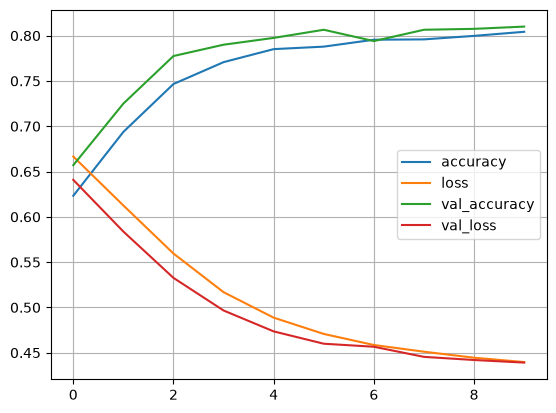

In [7]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()